# Аудит временной доступности макроэкономических данных для прогноза ключевой ставки ЦБ РФ

**Цель:** проверить, какие макроэкономические наблюдения могли быть доступны на дату заседания Банка России, и оценить чувствительность результатов к допущениям о сроках публикации.

Ноутбук состоит из двух частей:
1. Аудит временной доступности 28 макроэкономических признаков на датах заседаний ЦБ;
2. Описательный анализ архивных плановых календарей Росстата.

**Важно:** дата начала периода в исходных таблицах — метка наблюдения, а не дата публикации. Если фактическая дата выпуска неизвестна, датасет использует техническое допущение «первый день после окончания периода». Это допущение отдельно проверяется сценариями задержек и архивным календарём. Сценарные флаги не являются доказанными временными утечками.

**Граница прогноза:** в первой части предполагается, что прогноз формируется после заседания в дату `date`. Если в проекте прогноз должен формироваться до объявления решения, границу доступности необходимо пересмотреть.


## 1. Данные и структура проекта

Поместите четыре CSV-файла в папку `input/` рядом с ноутбуком:

- `key_rate_feature_alignment.csv` — соответствие заседаний ЦБ и макропризнаков;
- `features_monthly.csv` — 23 месячных признака;
- `features_quarterly.csv` — 5 квартальных признаков;
- `rosstat_calendar.csv` — зафиксированная архивная таблица календаря Росстата (394 записи, 11 столбцов).

Результаты расчётов сохраняются в папку `output/`. Исходные CSV не изменяются.


### Используемые библиотеки

In [72]:
%pip install --quiet --disable-pip-version-check requests==2.34.2 pandas==3.1.0 openpyxl==3.1.5 xlrd==2.0.2 beautifulsoup4==4.15.0 matplotlib==3.11.2 pypdf==6.21.4

Note: you may need to restart the kernel to use updated packages.


In [73]:
from pathlib import Path
import pandas as pd
import numpy as np

INPUT = Path("input")
OUTPUT = Path("output")
OUTPUT.mkdir(exist_ok=True)

def locate(stem):
    path = INPUT / f"{stem}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"Не найден файл {path}")
    return path

alignment = pd.read_csv(locate("key_rate_feature_alignment"))
monthly = pd.read_csv(locate("features_monthly"))
quarterly = pd.read_csv(locate("features_quarterly"))
for col in ["date", "source_period", "source_period_end", "availability_date_used", "release_date"]:
    alignment[col] = pd.to_datetime(alignment[col], errors="coerce")
for df in (monthly, quarterly):
    df["period"] = pd.to_datetime(df["period"], errors="coerce")

print("Строки alignment:", len(alignment))
print("Заседаний:", alignment.date.nunique(), "| признаков:", alignment.feature.nunique())
print("Правила доступности:\n", alignment.availability_rule.value_counts().to_string())
print("Месячных признаков:", monthly.shape[1] - 1)
print("Квартальных признаков:", quarterly.shape[1] - 1)


Строки alignment: 3108
Заседаний: 111 | признаков: 28
Правила доступности:
 availability_rule
period_end_assumption    1983
missing                  1100
source_release_date        25
Месячных признаков: 23
Квартальных признаков: 5


## 2. Правило доступности и сценарная проверка

В датасете используются три типа временной информации:

- `source_release_date` / `release_date` — фактическая дата публикации, если она известна;
- `period_end_assumption` — техническое допущение: первый календарный день после окончания отчётного периода;
- `missing` — дата доступности не определена.

Для производного признака дата доступности определяется наиболее поздней датой среди всех исходных наблюдений, необходимых для его расчёта. При сопоставлении с заседанием используется строгое условие: дата доступности должна быть **раньше** даты заседания.

Ниже оценивается, сколько наблюдений могло бы оказаться недоступным при условных задержках 7, 15 и 30 дней. Это анализ чувствительности к допущению, а не восстановление фактических дат публикации.

### Как устроено правило в ноутбуке сбора данных

Если дата выпуска известна, используется она. Если нет — берётся первый день после окончания месяца или квартала. Для признаков, построенных из нескольких исходных наблюдений, выбирается самая поздняя из соответствующих дат.


In [74]:
assumed = alignment.loc[
    alignment.availability_rule.eq("period_end_assumption")
    & alignment.value.notna()
    & alignment.source_period_end.notna()
].copy()

rows = []
for delay in (7, 15, 30):
    hypothetical_release = assumed.source_period_end + pd.to_timedelta(delay, unit="D")
    flagged = hypothetical_release >= assumed.date  # строгая граница: до заседания
    rows.append({"delay_days": delay, "potentially_unavailable": int(flagged.sum()),
                 "assumed_nonmissing": len(assumed)})
sensitivity = pd.DataFrame(rows)
display(sensitivity)
sensitivity.to_csv(OUTPUT / "sensitivity_7_15_30.csv", index=False)
print("Важно: это сценарии, не реальные даты публикации.")

,delay_days,potentially_unavailable,assumed_nonmissing
0,7,80,1983
1,15,553,1983
2,30,1653,1983


Важно: это сценарии, не реальные даты публикации.


## 3. Что изменится при гипотетической задержке 15 дней

Для каждого **помеченного** наблюдения подбираем последнее ненулевое значение из того же месячного или квартального ряда, которое успело бы стать доступным по условному правилу `конец периода + 15 дней < дата заседания`. Исходные строки с `source_release_date` остаются нетронутыми. Если подходящего более раннего значения нет, предлагаем `NaN`.

In [75]:
DELAY = 15
hypothetical_release = assumed.source_period_end + pd.Timedelta(days=DELAY)
flagged = assumed.loc[hypothetical_release >= assumed.date].copy()

monthly_cols = set(monthly.columns) - {"period"}
quarterly_cols = set(quarterly.columns) - {"period"}

replacements = []
for r in flagged.itertuples(index=False):
    if r.feature in monthly_cols:
        src, freq = monthly, "monthly"
        period_end = lambda s: s + pd.offsets.MonthEnd(0)
    elif r.feature in quarterly_cols:
        src, freq = quarterly, "quarterly"
        period_end = lambda s: s + pd.offsets.QuarterEnd(0)
    else:
        raise ValueError(f"Признак не найден в рядах: {r.feature}")
    eligible = src.loc[src[r.feature].notna(), ["period", r.feature]].copy()
    eligible["hypothetical_release"] = period_end(eligible.period) + pd.Timedelta(days=DELAY)
    eligible = eligible.loc[eligible.hypothetical_release < r.date].sort_values("period")
    if eligible.empty:
        new_period, new_value, status = pd.NaT, float("nan"), "no_eligible_value"
    else:
        chosen = eligible.iloc[-1]
        new_period, new_value, status = chosen.period, chosen[r.feature], "replaced"
    replacements.append({"date": r.date, "feature": r.feature, "frequency": freq,
        "original_period": r.source_period, "original_value": r.value,
        "new_period_15d": new_period, "new_value_15d": new_value, "status": status})

replacements = pd.DataFrame(replacements)
assert len(replacements) == len(flagged)
assert not replacements.duplicated(["date", "feature"]).any()
print("Помечено:", len(flagged))
print(replacements.status.value_counts().to_string())
replacements.to_csv(OUTPUT / "hypothetical_replacements_15d.csv", index=False)
display(replacements.head(10))

Помечено: 553
status
replaced             542
no_eligible_value     11


,date,feature,frequency,original_period,original_value,new_period_15d,new_value_15d,status
0,2013-10-14,cpi_food_mom_index__yoy_chained_pct,monthly,2013-09-01,6.325315,2013-08-01,6.495470,replaced
1,2013-10-14,cpi_mom_index__yoy_chained_pct,monthly,2013-09-01,6.132801,2013-08-01,6.492897,replaced
2,2013-10-14,cpi_nonfood_mom_index__yoy_chained_pct,monthly,2013-09-01,4.738606,2013-08-01,4.905321,replaced
3,2013-10-14,cpi_services_mom_index__yoy_chained_pct,monthly,2013-09-01,7.842110,2013-08-01,8.757761,replaced
4,2013-10-14,gdp_real_2021_bln_rub__yoy_change_1q_pp,quarterly,2013-07-01,-0.211950,2013-04-01,0.590658,replaced
5,2013-10-14,gdp_real_2021_sa_bln_rub__qoq_pct,quarterly,2013-07-01,-0.207337,2013-04-01,0.417488,replaced
6,2013-10-14,gdp_volume_yoy_index__yoy_pct,quarterly,2013-07-01,1.510458,2013-04-01,1.722408,replaced
7,2013-10-14,nominal_wages_rub__yoy_pct,monthly,2013-09-01,12.886598,2013-08-01,13.640252,replaced
8,2013-11-08,cpi_food_mom_index__yoy_chained_pct,monthly,2013-10-01,6.938751,2013-09-01,6.325315,replaced
9,2013-11-08,cpi_mom_index__yoy_chained_pct,monthly,2013-10-01,6.249013,2013-09-01,6.132801,replaced


## 4. Конкретный случай: 11 сентября 2026 года

Проверяем **исходную** строку `production_industry_yoy_index__yoy_pct` (август 2026 года). В исходном файле дата 01.09.2026 назначена по `period_end_assumption`, поле `release_date` пустое.

В статье [Интерфакса от 23.09.2026](https://www.interfax.ru/business/1118042) сообщается о снижении промышленного производства за август на **0,6%** со ссылкой на Росстат. Это совпадает со значением в CSV и показывает расхождение между условной датой доступности (01.09.2026), датой заседания (11.09.2026) и датой публичного сообщения (23.09.2026).

In [76]:
CASE_DATE = pd.Timestamp("2026-09-11")
CASE_FEATURE = "production_industry_yoy_index__yoy_pct"
case = alignment.loc[
    alignment.date.eq(CASE_DATE) & alignment.feature.eq(CASE_FEATURE),
    ["date", "feature", "value", "source_period", "source_period_end",
     "availability_rule", "availability_date_used", "release_date", "source_urls"]
].copy()
assert len(case) == 1, "Ожидалась одна строка кейса"
assert case.iloc[0].availability_rule == "period_end_assumption"
display(case.T.rename(columns={case.index[0]: "Значение"}))

PUBLIC_REPORT_DATE = pd.Timestamp("2026-09-23")  # дата сообщения Интерфакса
print("Заседание:", CASE_DATE.date())
print("Предполагаемая доступность:", case.iloc[0].availability_date_used.date())
print("Дата статьи Интерфакса:", PUBLIC_REPORT_DATE.date())
print("Разница между статьёй и заседанием:", (PUBLIC_REPORT_DATE - CASE_DATE).days, "дней")
print("Статус: выявлено расхождение дат")

,Значение
date,2026-09-11 00:00:00
feature,production_industry_yoy_index__yoy_pct
value,-0.6
source_period,2026-08-01 00:00:00
source_period_end,2026-08-31 00:00:00
availability_rule,period_end_assumption
availability_date_used,2026-09-01 00:00:00
release_date,NaT
source_urls,https://rosstat.gov.ru/storage/mediabank/ind_b...


Заседание: 2026-09-11
Предполагаемая доступность: 2026-09-01
Дата статьи Интерфакса: 2026-09-23
Разница между статьёй и заседанием: 12 дней
Статус: выявлено расхождение дат


## 5. Другие показатели на том же заседании

Показываем, что риск не ограничивается одним столбцом. Это **не** означает, что все перечисленные признаки были опубликованы после заседания: для каждого нужна отдельная проверка.

In [77]:
keywords = "cpi|wages|production|ppi"
other = alignment.loc[
    alignment.date.eq(CASE_DATE) & alignment.feature.str.contains(keywords, case=False, na=False),
    ["feature", "source_period", "value", "availability_rule", "availability_date_used", "release_date"]
].sort_values("feature")
display(other)


,feature,source_period,value,availability_rule,availability_date_used,release_date
3080,core_cpi_mom_index__mom_mean_3m_pct,2026-07-01,0.490000,source_release_date,2026-08-12,2026-08-12
3081,core_cpi_yoy_index__yoy_pct,2026-07-01,5.220000,source_release_date,2026-08-12,2026-08-12
3082,cpi_food_mom_index__yoy_chained_pct,2026-08-01,5.086683,period_end_assumption,2026-09-01,NaT
3083,cpi_mom_index__yoy_chained_pct,2026-08-01,6.336532,period_end_assumption,2026-09-01,NaT
3084,cpi_nonfood_mom_index__yoy_chained_pct,2026-08-01,6.521070,period_end_assumption,2026-09-01,NaT
3085,cpi_services_mom_index__yoy_chained_pct,2026-08-01,7.841665,period_end_assumption,2026-09-01,NaT
3090,nominal_wages_rub__yoy_pct,2026-08-01,10.927573,period_end_assumption,2026-09-01,NaT
3093,ppi_industry_mom_index__yoy_chained_pct,2026-08-01,6.542123,period_end_assumption,2026-09-01,NaT
3094,ppi_manufacturing_mom_index__yoy_chained_pct,2026-08-01,7.660602,period_end_assumption,2026-09-01,NaT
3095,ppi_mining_mom_index__yoy_chained_pct,2026-08-01,5.943883,period_end_assumption,2026-09-01,NaT


## 6. Проверки качества и итоговые файлы

Проверяем, что известные даты релиза не были заменены сценарием, а предложенные новые периоды не относятся к будущему относительно исходного периода.

In [78]:
assert (flagged.availability_rule == "period_end_assumption").all()
assert not flagged.duplicated(["date", "feature"]).any()
valid = replacements.loc[replacements.status.eq("replaced")]
assert (valid.new_period_15d <= valid.original_period).all()

summary = pd.DataFrame([
    {"metric": "meetings", "value": alignment.date.nunique()},
    {"metric": "features", "value": alignment.feature.nunique()},
    {"metric": "period_end_assumption_nonmissing", "value": len(assumed)},
    {"metric": "scenario_15d_flagged", "value": len(flagged)},
    {"metric": "scenario_15d_replaced", "value": int((replacements.status == "replaced").sum())},
    {"metric": "scenario_15d_no_eligible_value", "value": int((replacements.status == "no_eligible_value").sum())},
])
display(summary)
print("Готово: результаты в папке output")

,metric,value
0,meetings,111
1,features,28
2,period_end_assumption_nonmissing,1983
3,scenario_15d_flagged,553
4,scenario_15d_replaced,542
5,scenario_15d_no_eligible_value,11


Готово: результаты в папке output


## 7. Выводы

1. **Подтверждено кодом и CSV:** для большого числа признаков используется `period_end_assumption` — дата, рассчитанная как следующий день после конца периода, без фактического подтверждения даты выпуска.
2. **Сценарный анализ:** задержки 7, 15 и 30 дней показывают, насколько чувствителен датасет к этому допущению. Число помеченных значений **не следует** называть числом доказанных утечек.
3. **Кейс 2026:** августовское промышленное производство (−0,6%) используется в признаках заседания 11.09.2026 с условной доступностью 01.09.2026; статья Интерфакса с этим числом датирована 23.09.2026. Это конкретный пример высокого риска временной утечки.
4. **Ограничения:** исторические версии и пересмотры статистики не восстановлены.

**Ссылки для проверки:** [Интерфакс, 23.09.2026](https://www.interfax.ru/business/1118042); [календарь Росстата](https://rosstat.gov.ru/statistics/monitoring/sdds/calendar).

---

# Часть II. Архивный календарь Росстата

Вторая часть использует контрольную версию **`rosstat_calendar.csv`**: 394 записи, 11 исходных столбцов и 14 архивных источников (снимков календаря Росстата). Повторения между снимками сохраняются, поскольку отражают историю версий календаря.

Календарь содержит **плановые**, а не подтверждённые фактические даты публикаций.


## 8. Загрузка архивной таблицы календаря

Загружаем единую таблицу `rosstat_calendar.csv`, содержащую 394 записи из 14 архивных снимков календаря Росстата. Проверяем структуру данных и корректность форматов дат для дальнейшего анализа плановых сроков публикации статистических показателей.


In [79]:
calendar = pd.read_csv(
    locate("rosstat_calendar"),
    encoding="utf-8-sig"
)

required_calendar_columns = [
    "snapshot_id", "calendar_snapshot_date", "indicator",
    "calendar_month", "planned_day", "planned_date",
    "reference_period", "raw_cell", "calendar_note",
    "source_url", "parse_status"
]
missing_columns = [c for c in required_calendar_columns if c not in calendar.columns]
if missing_columns:
    raise ValueError(f"В rosstat_calendar.csv отсутствуют столбцы: {missing_columns}")

calendar["calendar_snapshot_date"] = pd.to_datetime(
    calendar["calendar_snapshot_date"], errors="coerce"
)
calendar["planned_date"] = pd.to_datetime(calendar["planned_date"], errors="coerce")
calendar["planned_day"] = pd.to_numeric(calendar["planned_day"], errors="coerce").astype("Int64")
calendar["reference_period"] = calendar["reference_period"].fillna("").astype(str).str.strip()
calendar["indicator"] = calendar["indicator"].fillna("").astype(str).str.strip()

print(f"Записей в таблице: {len(calendar):,}")
print(f"Архивных снимков: {calendar['snapshot_id'].nunique():,}")
print(f"Период снимков: {calendar.calendar_snapshot_date.min().date()} — "
      f"{calendar.calendar_snapshot_date.max().date()}")
print(f"Строк с плановой датой: {calendar.planned_date.notna().sum():,}")
print("Столбцов:", len(calendar.columns))
display(calendar.head())

Записей в таблице: 394
Архивных снимков: 14
Период снимков: 2022-05-16 — 2026-03-17
Строк с плановой датой: 394
Столбцов: 11


,snapshot_id,calendar_snapshot_date,indicator,calendar_month,planned_day,planned_date,reference_period,raw_cell,calendar_note,source_url,parse_status
0,Росстат — Календарь выпуска данных.htm,2022-05-16,Национальные счета,Июль/22,11,2022-07-11,1 кв./22,11 (01 кв./22),NaN,https://web.archive.org/web/20220516111246/htt...,ok
1,Росстат — Календарь выпуска данных.htm,2022-05-16,Индекс промышленного производства,Июнь/22,3,2022-06-03,Апрель/22,3 (Апрель/22) 30 (Май/22),Данные за апрель 2022 года будут опубликованы ...,https://web.archive.org/web/20220516111246/htt...,ok
2,Росстат — Календарь выпуска данных.htm,2022-05-16,Индекс промышленного производства,Июнь/22,30,2022-06-30,Май/22,3 (Апрель/22) 30 (Май/22),Данные за апрель 2022 года будут опубликованы ...,https://web.archive.org/web/20220516111246/htt...,ok
3,Росстат — Календарь выпуска данных.htm,2022-05-16,Индекс промышленного производства,Июль/22,29,2022-07-29,Июнь/22,29 (Июнь/22),Данные за апрель 2022 года будут опубликованы ...,https://web.archive.org/web/20220516111246/htt...,ok
4,Росстат — Календарь выпуска данных.htm,2022-05-16,Индекс промышленного производства,Август/22,31,2022-08-31,Июль/22,31 (Июль/22),Данные за апрель 2022 года будут опубликованы ...,https://web.archive.org/web/20220516111246/htt...,ok


## 9. Реестр снимков

Формируем сводную таблицу архивных снимков календаря Росстата с указанием дат снимков, количества записей, уникальных статистических показателей, плановых дат публикаций и ссылок на архивные источники.


In [80]:
snapshot_register = (
    calendar.groupby(
        ["calendar_snapshot_date", "snapshot_id"], dropna=False
    )
    .agg(
        records=("indicator", "size"),
        indicators=("indicator", "nunique"),
        planned_dates=("planned_date", "nunique"),
        missing_planned_dates=("planned_date", lambda s: int(s.isna().sum())),
        source_url=("source_url", "first")
    )
    .reset_index()
    .sort_values("calendar_snapshot_date")
)
display(snapshot_register)
print("Всего архивных снимков:", len(snapshot_register))

,calendar_snapshot_date,snapshot_id,records,indicators,planned_dates,missing_planned_dates,source_url
0,2022-05-16,Росстат — Календарь выпуска данных.htm,27,9,6,0,https://web.archive.org/web/20220516111246/htt...
1,2022-06-17,Росстат — Календарь выпуска данных2.htm,31,9,6,0,https://web.archive.org/web/20220617080346/htt...
2,2022-09-27,Росстат — Календарь выпуска данных3.htm,28,9,5,0,https://web.archive.org/web/20220927231658/htt...
3,2023-01-31,Росстат — Календарь выпуска данных4.htm,31,10,5,0,https://web.archive.org/web/20230131160957/htt...
4,2023-04-20,Росстат — Календарь выпуска данных5.html,35,9,6,0,https://web.archive.org/web/20230420184316/htt...
5,2023-06-02,Росстат — Календарь выпуска данных6.html,27,9,5,0,https://web.archive.org/web/20230602142830/htt...
6,2023-10-01,Росстат — Календарь выпуска данных7.html,23,10,6,0,https://web.archive.org/web/20231001153718/htt...
7,2023-12-08,Росстат — Календарь выпуска данных8.html,22,10,5,0,https://web.archive.org/web/20231208215518/htt...
8,2024-03-06,Росстат — Календарь выпуска данных9.html,29,10,5,0,https://web.archive.org/web/20240306195935/htt...
9,2024-05-22,Росстат — Календарь выпуска данных10.html,27,9,4,0,https://web.archive.org/web/20240522184217/htt...


Всего архивных снимков: 14


### Контроль качества архивного календаря

Проверяем статусы разбора, наличие плановых дат и согласованность `planned_day` с `planned_date`.


In [81]:
# Контроль качества календаря.
print("Статусы парсинга:")
display(calendar["parse_status"].value_counts(dropna=False).rename("records").to_frame())

print("Записи без плановой даты:")
display(calendar[calendar["planned_date"].isna()])

calendar["planned_day_check"] = np.where(
    calendar["planned_date"].notna()
    & calendar["planned_day"].notna()
    & calendar["planned_date"].dt.day.eq(calendar["planned_day"]),
    "ok", "check"
)
print("Проверка planned_day:")
display(calendar["planned_day_check"].value_counts(dropna=False).rename("records").to_frame())



Статусы парсинга:


,records
parse_status,
ok,394


Записи без плановой даты:


,snapshot_id,calendar_snapshot_date,indicator,calendar_month,planned_day,planned_date,reference_period,raw_cell,calendar_note,source_url,parse_status


Проверка planned_day:


,records
planned_day_check,
ok,394


## 10. Плановый лаг между окончанием периода и датой публикации

В этом разделе оценивается, сколько календарных дней проходит между окончанием отчётного периода и **плановой** датой публикации в архивном календаре Росстата.

Методика расчёта:

1. Для каждой пары «показатель + отчётный период» выбирается последний архивный снимок, в котором эта пара присутствует.
2. Если в выбранном снимке для одной пары указано несколько плановых дат, все они сохраняются.
3. В расчёт попадают только периоды, которые представлены ненулевыми значениями соответствующих признаков в `features_monthly.csv` или `features_quarterly.csv` и сопоставлены с категорией календаря.
4. Годовые периоды не включаются в сводку месячных и квартальных признаков.
5. Рассчитываются среднее, медиана, минимум, максимум и число наблюдений.

**Ограничение интерпретации:** это плановый лаг по последним доступным версиям архивных записей, а не фактическая задержка публикации. Он не доказывает, что статистика действительно стала доступна в указанную дату. Кроме того, календарь покрывает не все 28 признаков и местами соответствует только широкой категории показателей.


Сводный плановый лаг:


,observations,mean_lag_days,median_lag_days,min_lag_days,max_lag_days
0,219,42.9,34.0,28,107


Плановый лаг по периодичности:


,period_frequency,observations,mean_lag_days,median_lag_days,min_lag_days,max_lag_days
0,monthly,205,39.0,34.0,28,71
1,quarterly,14,100.4,101.0,91,107


Плановый лаг по показателям:


,indicator,period_frequency,observations,mean_lag_days,median_lag_days,min_lag_days,max_lag_days
0,Индекс промышленного производства,monthly,41,33.0,33.0,28,40
1,Индексы цен: потребительские цены,monthly,41,32.9,33.0,28,40
2,Индексы цен: цены производителей промышленной ...,monthly,41,32.9,33.0,28,40
4,Рынок труда: безработица,monthly,41,33.0,33.0,28,40
5,Рынок труда: заработная плата,monthly,41,63.3,63.0,58,71
3,Национальные счета,quarterly,14,100.4,101.0,91,107


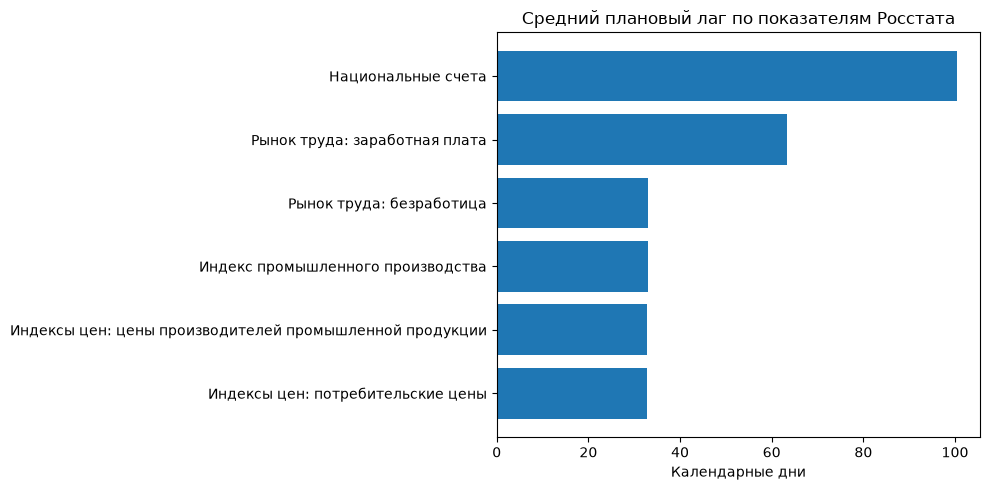

In [82]:
# Внутренняя карта соответствия признаков категориям календаря.
# Компактная карта соответствий встроена в ноутбук — отдельный CSV не нужен.
feature_calendar_map = pd.DataFrame([{'feature': 'cpi_mom_index__yoy_chained_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индексы цен: потребительские цены', 'interpretation': 'Календарь для ИПЦ в целом; отдельные даты для базового ИПЦ, продовольствия, непродовольствия и услуг не доказаны'}, {'feature': 'cpi_food_mom_index__yoy_chained_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индексы цен: потребительские цены', 'interpretation': 'Календарь для ИПЦ в целом; отдельные даты для базового ИПЦ, продовольствия, непродовольствия и услуг не доказаны'}, {'feature': 'cpi_nonfood_mom_index__yoy_chained_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индексы цен: потребительские цены', 'interpretation': 'Календарь для ИПЦ в целом; отдельные даты для базового ИПЦ, продовольствия, непродовольствия и услуг не доказаны'}, {'feature': 'cpi_services_mom_index__yoy_chained_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индексы цен: потребительские цены', 'interpretation': 'Календарь для ИПЦ в целом; отдельные даты для базового ИПЦ, продовольствия, непродовольствия и услуг не доказаны'}, {'feature': 'core_cpi_mom_index__mom_mean_3m_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индексы цен: потребительские цены', 'interpretation': 'Календарь для ИПЦ в целом; отдельные даты для базового ИПЦ, продовольствия, непродовольствия и услуг не доказаны'}, {'feature': 'core_cpi_yoy_index__yoy_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индексы цен: потребительские цены', 'interpretation': 'Календарь для ИПЦ в целом; отдельные даты для базового ИПЦ, продовольствия, непродовольствия и услуг не доказаны'}, {'feature': 'ppi_industry_mom_index__yoy_chained_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индексы цен: цены производителей промышленной продукции', 'interpretation': 'Общий график цен производителей; отраслевые подиндексы отдельно не указаны'}, {'feature': 'ppi_manufacturing_mom_index__yoy_chained_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индексы цен: цены производителей промышленной продукции', 'interpretation': 'Общий график цен производителей; отраслевые подиндексы отдельно не указаны'}, {'feature': 'ppi_mining_mom_index__yoy_chained_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индексы цен: цены производителей промышленной продукции', 'interpretation': 'Общий график цен производителей; отраслевые подиндексы отдельно не указаны'}, {'feature': 'production_industry_mom_index__mom_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индекс промышленного производства', 'interpretation': 'График промышленного производства в целом; производство/добыча и MoM/YoY не разделены'}, {'feature': 'production_industry_yoy_index__yoy_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индекс промышленного производства', 'interpretation': 'График промышленного производства в целом; производство/добыча и MoM/YoY не разделены'}, {'feature': 'production_manufacturing_mom_index__mom_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индекс промышленного производства', 'interpretation': 'График промышленного производства в целом; производство/добыча и MoM/YoY не разделены'}, {'feature': 'production_manufacturing_yoy_index__yoy_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индекс промышленного производства', 'interpretation': 'График промышленного производства в целом; производство/добыча и MoM/YoY не разделены'}, {'feature': 'production_mining_mom_index__mom_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индекс промышленного производства', 'interpretation': 'График промышленного производства в целом; производство/добыча и MoM/YoY не разделены'}, {'feature': 'production_mining_yoy_index__yoy_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Индекс промышленного производства', 'interpretation': 'График промышленного производства в целом; производство/добыча и MoM/YoY не разделены'}, {'feature': 'unemployment_rate_3month_pct', 'frequency': 'monthly', 'coverage': 'Близкое прямое соответствие', 'calendar_indicator': 'Рынок труда: безработица', 'interpretation': 'Соответствие по тематике; 3-месячная агрегация требует доступности всех входных месяцев'}, {'feature': 'nominal_wages_rub__yoy_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Рынок труда: заработная плата', 'interpretation': 'Номинальная/реальная зарплата отдельно в календаре не различены'}, {'feature': 'real_wages_yoy_index__yoy_pct', 'frequency': 'monthly', 'coverage': 'Групповой прокси', 'calendar_indicator': 'Рынок труда: заработная плата', 'interpretation': 'Номинальная/реальная зарплата отдельно в календаре не различены'}, {'feature': 'retail_turnover_nominal_mln_rub__mom_pct', 'frequency': 'monthly', 'coverage': 'Нет строки', 'calendar_indicator': '—', 'interpretation': 'Отдельной строки розничной торговли в имеющихся снимках нет'}, {'feature': 'retail_real_mom_index__mom_pct', 'frequency': 'monthly', 'coverage': 'Нет строки', 'calendar_indicator': '—', 'interpretation': 'Отдельной строки розничной торговли в имеющихся снимках нет'}, {'feature': 'retail_real_yoy_index__yoy_pct', 'frequency': 'monthly', 'coverage': 'Нет строки', 'calendar_indicator': '—', 'interpretation': 'Отдельной строки розничной торговли в имеющихся снимках нет'}, {'feature': 'paid_services_volume_mom_index__mom_pct', 'frequency': 'monthly', 'coverage': 'Нет строки', 'calendar_indicator': '—', 'interpretation': 'Отдельной строки платных услуг в имеющихся снимках нет'}, {'feature': 'paid_services_volume_yoy_index__yoy_pct', 'frequency': 'monthly', 'coverage': 'Нет строки', 'calendar_indicator': '—', 'interpretation': 'Отдельной строки платных услуг в имеющихся снимках нет'}, {'feature': 'gdp_real_2021_bln_rub__yoy_change_1q_pp', 'frequency': 'quarterly', 'coverage': 'Неполный прокси', 'calendar_indicator': 'Национальные счета', 'interpretation': 'Национальные счета шире ВВП; не подтверждены конкретная версия ВВП, сезонная корректировка и ревизии'}, {'feature': 'gdp_real_2021_sa_bln_rub__qoq_pct', 'frequency': 'quarterly', 'coverage': 'Неполный прокси', 'calendar_indicator': 'Национальные счета', 'interpretation': 'Национальные счета шире ВВП; не подтверждены конкретная версия ВВП, сезонная корректировка и ревизии'}, {'feature': 'gdp_volume_yoy_index__yoy_pct', 'frequency': 'quarterly', 'coverage': 'Неполный прокси', 'calendar_indicator': 'Национальные счета', 'interpretation': 'Национальные счета шире ВВП; не подтверждены конкретная версия ВВП, сезонная корректировка и ревизии'}, {'feature': 'investment_real_ytd_yoy_index__ytd_yoy_pct', 'frequency': 'quarterly', 'coverage': 'Нет строки', 'calendar_indicator': '—', 'interpretation': 'Отдельной строки инвестиций в имеющихся снимках нет'}, {'feature': 'real_disposable_income_yoy_index__yoy_pct', 'frequency': 'quarterly', 'coverage': 'Нет строки', 'calendar_indicator': '—', 'interpretation': 'Отдельной строки реальных располагаемых доходов в имеющихся снимках нет'}])

# Разбор месячных и квартальных периодов из reference_period.
import re
import matplotlib.pyplot as plt
from pandas.tseries.offsets import MonthEnd

RU_MONTHS = {
    "январь": 1, "февраль": 2, "март": 3, "апрель": 4,
    "май": 5, "июнь": 6, "июль": 7, "август": 8,
    "сентябрь": 9, "октябрь": 10, "ноябрь": 11, "декабрь": 12,
}

def parse_calendar_period(value):
    """Возвращает начало, конец и частоту отчётного периода."""
    s = str(value).strip().lower().replace("ё", "е")

    quarter = re.fullmatch(r"([1-4])\s*кв\.?\s*/?\s*(\d{2,4})", s)
    if quarter:
        q, year = int(quarter.group(1)), int(quarter.group(2))
        year = year + 2000 if year < 100 else year
        start = pd.Timestamp(year, (q - 1) * 3 + 1, 1)
        end = pd.Timestamp(year, q * 3, 1) + MonthEnd(0)
        return start, end, "quarterly"

    month = re.fullmatch(r"([а-я]+)\s*/\s*(\d{2,4})", s)
    if month and month.group(1) in RU_MONTHS:
        year = int(month.group(2))
        year = year + 2000 if year < 100 else year
        start = pd.Timestamp(year, RU_MONTHS[month.group(1)], 1)
        return start, start + MonthEnd(0), "monthly"

    return pd.NaT, pd.NaT, "unknown"


parsed = calendar["reference_period"].map(parse_calendar_period)
calendar["period_start"] = [item[0] for item in parsed]
calendar["period_end"] = [item[1] for item in parsed]
calendar["period_frequency"] = [item[2] for item in parsed]

# Периоды, реально присутствующие в ненулевых значениях признаков.
source_frames = {"monthly": monthly, "quarterly": quarterly}
mapped_features = feature_calendar_map.loc[
    feature_calendar_map["calendar_indicator"].ne("—")
].copy()

available_periods = {}
features_by_indicator = {}

for indicator, group in mapped_features.groupby("calendar_indicator"):
    periods = set()
    feature_names = []

    for row in group.itertuples(index=False):
        source = source_frames[row.frequency]
        if row.feature not in source.columns:
            continue

        observed = source.loc[source[row.feature].notna(), "period"].dropna()
        periods.update(observed.dt.to_period("M").dt.to_timestamp())
        feature_names.append(row.feature)

    available_periods[indicator] = periods
    features_by_indicator[indicator] = feature_names

# Берём последнюю версию каждой пары «показатель + отчётный период».
last_snapshot = calendar.groupby(
    ["indicator", "reference_period"]
)["calendar_snapshot_date"].transform("max")

latest_versions = calendar.loc[
    calendar["calendar_snapshot_date"].eq(last_snapshot)
].copy()

lag_parts = []
for indicator, periods in available_periods.items():
    selected = latest_versions.loc[
        latest_versions["indicator"].eq(indicator)
        & latest_versions["period_start"].isin(periods)
        & latest_versions["period_frequency"].isin(["monthly", "quarterly"])
        & latest_versions["planned_date"].notna()
        & latest_versions["period_end"].notna()
    ].copy()

    if selected.empty:
        continue

    selected["lag_days"] = (
        selected["planned_date"] - selected["period_end"]
    ).dt.days
    selected["mapped_features"] = ", ".join(features_by_indicator[indicator])
    lag_parts.append(selected)

if not lag_parts:
    raise ValueError("Не удалось сопоставить календарные периоды с признаками.")

rosstat_lag_detail = pd.concat(lag_parts, ignore_index=True)

lag_by_indicator = (
    rosstat_lag_detail.groupby(["indicator", "period_frequency"])
    .agg(
        observations=("lag_days", "size"),
        mean_lag_days=("lag_days", "mean"),
        median_lag_days=("lag_days", "median"),
        min_lag_days=("lag_days", "min"),
        max_lag_days=("lag_days", "max"),
    )
    .reset_index()
    .sort_values(["period_frequency", "indicator"])
)

lag_by_frequency = (
    rosstat_lag_detail.groupby("period_frequency")
    .agg(
        observations=("lag_days", "size"),
        mean_lag_days=("lag_days", "mean"),
        median_lag_days=("lag_days", "median"),
        min_lag_days=("lag_days", "min"),
        max_lag_days=("lag_days", "max"),
    )
    .reset_index()
)

overall_lag = pd.DataFrame([{
    "observations": len(rosstat_lag_detail),
    "mean_lag_days": rosstat_lag_detail["lag_days"].mean(),
    "median_lag_days": rosstat_lag_detail["lag_days"].median(),
    "min_lag_days": rosstat_lag_detail["lag_days"].min(),
    "max_lag_days": rosstat_lag_detail["lag_days"].max(),
}])

print("Сводный плановый лаг:")
display(overall_lag.round(1))
print("Плановый лаг по периодичности:")
display(lag_by_frequency.round(1))
print("Плановый лаг по показателям:")
display(lag_by_indicator.round(1))

# График среднего планового лага по категориям календаря.
plot_data = lag_by_indicator.sort_values("mean_lag_days")
plt.figure(figsize=(10, 5))
plt.barh(plot_data["indicator"], plot_data["mean_lag_days"])
plt.xlabel("Календарные дни")
plt.ylabel("")
plt.title("Средний плановый лаг по показателям Росстата")
plt.tight_layout()
plt.show()

# Выгрузки детализации и сводных таблиц.
lag_detail_columns = [
    "calendar_snapshot_date", "snapshot_id", "indicator",
    "reference_period", "period_frequency", "period_start", "period_end",
    "planned_date", "lag_days", "mapped_features", "raw_cell",
    "calendar_note", "source_url",
]
rosstat_lag_detail[lag_detail_columns].to_csv(
    OUTPUT / "rosstat_planned_release_lags_detail.csv",
    index=False, encoding="utf-8-sig"
)
lag_by_indicator.to_csv(
    OUTPUT / "rosstat_planned_release_lags_by_indicator.csv",
    index=False, encoding="utf-8-sig"
)
lag_by_frequency.to_csv(
    OUTPUT / "rosstat_planned_release_lags_by_frequency.csv",
    index=False, encoding="utf-8-sig"
)


## 11. Контроль качества и экспорт результатов

Проводим итоговую проверку полноты и согласованности данных архивного календаря Росстата. Формируем сводную таблицу результатов проверки и сохраняем реестр архивных снимков для дальнейшего использования.


In [83]:
quality_summary = pd.DataFrame([
    {"check": "rows_in_master", "value": len(calendar)},
    {"check": "unique_snapshot_ids", "value": calendar.snapshot_id.nunique()},
    {"check": "rows_with_planned_date", "value": int(calendar.planned_date.notna().sum())},
    {"check": "rows_without_planned_date", "value": int(calendar.planned_date.isna().sum())},
    {"check": "rows_without_reference_period", "value": int(calendar.reference_period.eq("").sum())},
    {"check": "unique_source_urls", "value": calendar.source_url.nunique()},
    {"check": "planned_day_check_failures", "value": int(calendar.planned_day_check.ne("ok").sum())}
])
display(quality_summary)

snapshot_register.to_csv(OUTPUT / "rosstat_snapshot_register.csv",
                         index=False, encoding="utf-8-sig")
quality_summary.to_csv(OUTPUT / "rosstat_archive_quality_summary.csv",
                       index=False, encoding="utf-8-sig")



,check,value
0,rows_in_master,394
1,unique_snapshot_ids,14
2,rows_with_planned_date,394
3,rows_without_planned_date,0
4,rows_without_reference_period,0
5,unique_source_urls,14
6,planned_day_check_failures,0


## 12. Итоговая интерпретация

Проведённый анализ показал, что при формировании датасета для прогнозирования ключевой ставки ЦБ РФ в ряде случаев используется условная дата доступности макроэкономических данных — первый день после окончания отчётного периода. Такой подход не учитывает фактические сроки публикации статистики и может приводить к использованию информации, которая ещё не была доступна на дату заседания ЦБ.

Сценарный анализ с задержками 7, 15 и 30 дней позволил оценить чувствительность датасета к принятому допущению. Выявленные случаи рассматриваются как потенциальные риски временной утечки, а не как доказанные ошибки.

Дополнительно на основе архивного календаря Росстата были рассчитаны плановые лаги публикации статистических показателей, используемых в датасете. Полученные результаты показывают, что между окончанием отчётного периода и запланированной публикацией данных существует временной разрыв. При этом плановые даты могут отличаться от фактических.

**В дальнейшем для повышения временной корректности датасета можно рассмотреть использование среднего исторического лага публикации по каждому статистическому показателю вместо допущения о доступности данных на следующий день после окончания отчётного периода.** Такой подход позволит точнее оценивать предполагаемые даты доступности и потенциально снизить риск временных утечек. При этом лаг необходимо рассчитывать только на основе информации, доступной на момент прогноза, а при наличии подтверждённых дат публикаций использовать именно их.

Таким образом, на текущем этапе выявлены основные ограничения временной привязки макроэкономических данных и предложен возможный подход к их устранению.
